In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE
import joblib
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix


In [ ]:
# Load dataset (modify the path if needed)
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Cancer csv/kidney_disease.csv')

print("Shape:", df.shape)
df.head(5)

Shape: (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [ ]:
df.describe()

,id,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,399.000000,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [ ]:
# dropping id column
df.drop('id', axis = 1, inplace = True)

In [ ]:
# rename column names to make it more user-friendly

df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'aanemia', 'class']

In [ ]:
df.columns = df.columns.str.lower().str.strip().str.replace(" ", "_")
df.head(5)


,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [ ]:
print("\nColumn Names:")
print(df.columns)



Column Names:
Index(['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar',
       'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria',
       'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
       'potassium', 'haemoglobin', 'packed_cell_volume',
       'white_blood_cell_count', 'red_blood_cell_count', 'hypertension',
       'diabetes_mellitus', 'coronary_artery_disease', 'appetite',
       'peda_edema', 'aanemia', 'class'],
      dtype='object')


In [ ]:
print("\nMissing Values Count:")
print(df.isnull().sum())


Missing Values Count:
age                          9
blood_pressure              12
specific_gravity            47
albumin                     46
sugar                       49
red_blood_cells            152
pus_cell                    65
pus_cell_clumps              4
bacteria                     4
blood_glucose_random        44
blood_urea                  19
serum_creatinine            17
sodium                      87
potassium                   88
haemoglobin                 52
packed_cell_volume          70
white_blood_cell_count     105
red_blood_cell_count       130
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
peda_edema                   1
aanemia                      1
class                        0
dtype: int64


# **Fixing inconsistent text values**
- my  dataset has values like:

- "yes", "no"

- "normal", "abnormal"

- "present", "notpresent"

- "good", "poor"

Some values with trailing spaces (" yes", "no ")

In [ ]:
# Strip spaces and convert all strings to lowercase
df = df.applymap(lambda x: x.strip().lower() if isinstance(x, str) else x)


In [ ]:
# replace incorrect values

df['diabetes_mellitus'].replace(to_replace = {'\tno':'no','\tyes':'yes',' yes':'yes'},inplace=True)

df['coronary_artery_disease'] = df['coronary_artery_disease'].replace(to_replace = '\tno', value='no')

df['class'] = df['class'].replace(to_replace = {'ckd\t': 'ckd', 'notckd': 'not ckd'})

In [ ]:
df['class'] = df['class'].map({'ckd': 0, 'not ckd': 1})
df['class'] = pd.to_numeric(df['class'], errors='coerce')

In [ ]:
cols = ['diabetes_mellitus', 'coronary_artery_disease', 'class']

for col in cols:
    print(f"{col} has {df[col].unique()} values\n")

diabetes_mellitus has ['yes' 'no' nan] values

coronary_artery_disease has ['no' 'yes' nan] values

class has [0 1] values



# **Convert numeric columns stored as strings**

Some numeric columns pcv, wc, rc have values like:

- "45","6200","4.9".

But read as object type → must convert to numeric.

In [ ]:
num_convert = ['packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count']

for col in num_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [ ]:
 #--- feature dtype lists (exclude target) ---
feature_cols = [c for c in df.columns if c != 'type']
cat_cols = df[feature_cols].select_dtypes(include=['object']).columns.tolist()
num_cols = df[feature_cols].select_dtypes(include=['int64', 'float64']).columns.tolist()

print("➡ Categorical Columns (features only):", cat_cols)
print("➡ Numerical Columns (features only):", num_cols)

➡ Categorical Columns (features only): ['red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema', 'aanemia']
➡ Numerical Columns (features only): ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium', 'potassium', 'haemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count', 'class']


In [ ]:
# looking at unique values in categorical columns

for col in cat_cols:
    print(f"{col} has {df[col].unique()} values\n")

red_blood_cells has [nan 'normal' 'abnormal'] values

pus_cell has ['normal' 'abnormal' nan] values

pus_cell_clumps has ['notpresent' 'present' nan] values

bacteria has ['notpresent' 'present' nan] values

hypertension has ['yes' 'no' nan] values

diabetes_mellitus has ['yes' 'no' nan] values

coronary_artery_disease has ['no' 'yes' nan] values

appetite has ['good' 'poor' nan] values

peda_edema has ['no' 'yes' nan] values

aanemia has ['no' 'yes' nan] values



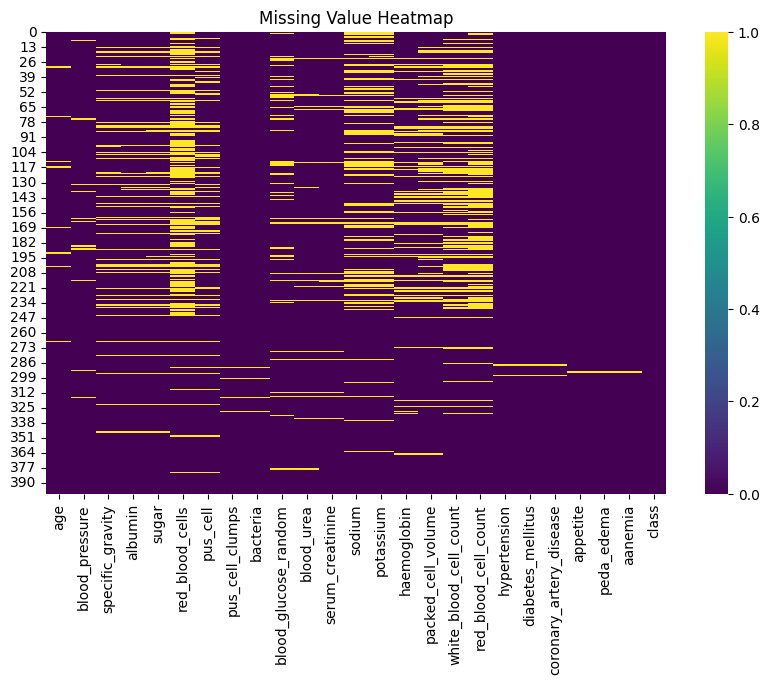

In [ ]:
#Heatmap  of missing patterns
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cmap="viridis")
plt.title("Missing Value Heatmap")
plt.show()


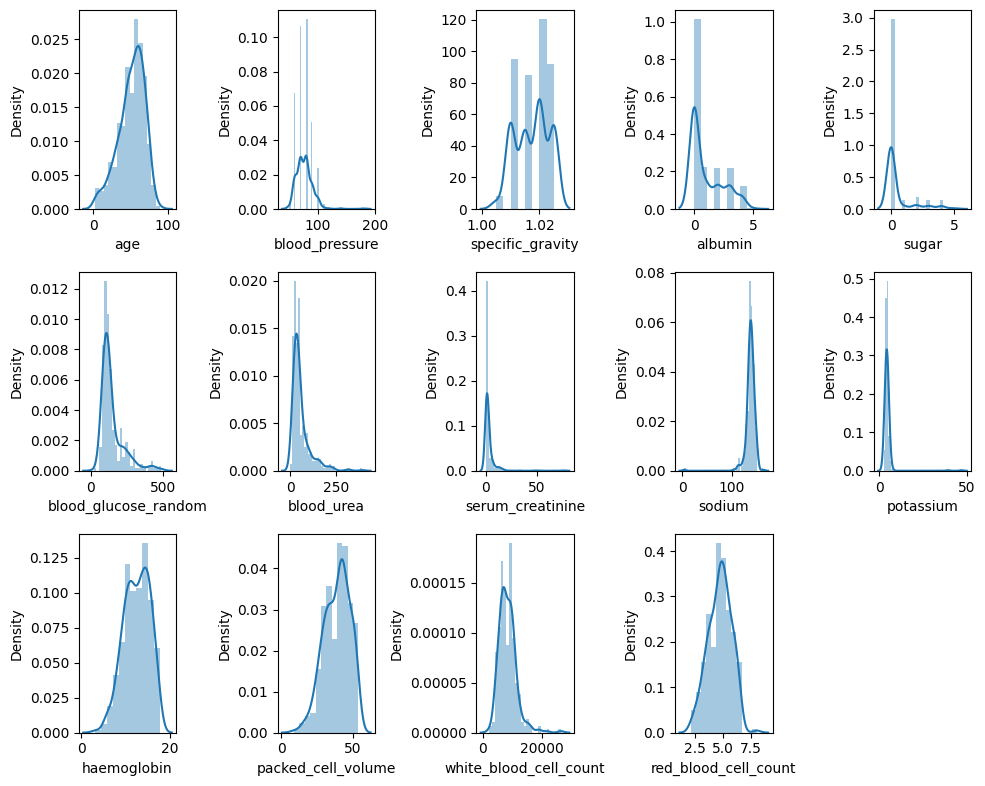

In [ ]:
# checking numerical features distribution

plt.figure(figsize = (10, 8))
plotnumber = 1

for column in num_cols:
    if plotnumber <= 14:
        ax = plt.subplot(3, 5, plotnumber)
        sns.distplot(df[column])
        plt.xlabel(column)

    plotnumber += 1

plt.tight_layout()
plt.show()

we can see t hat skewness is present in someof the columns

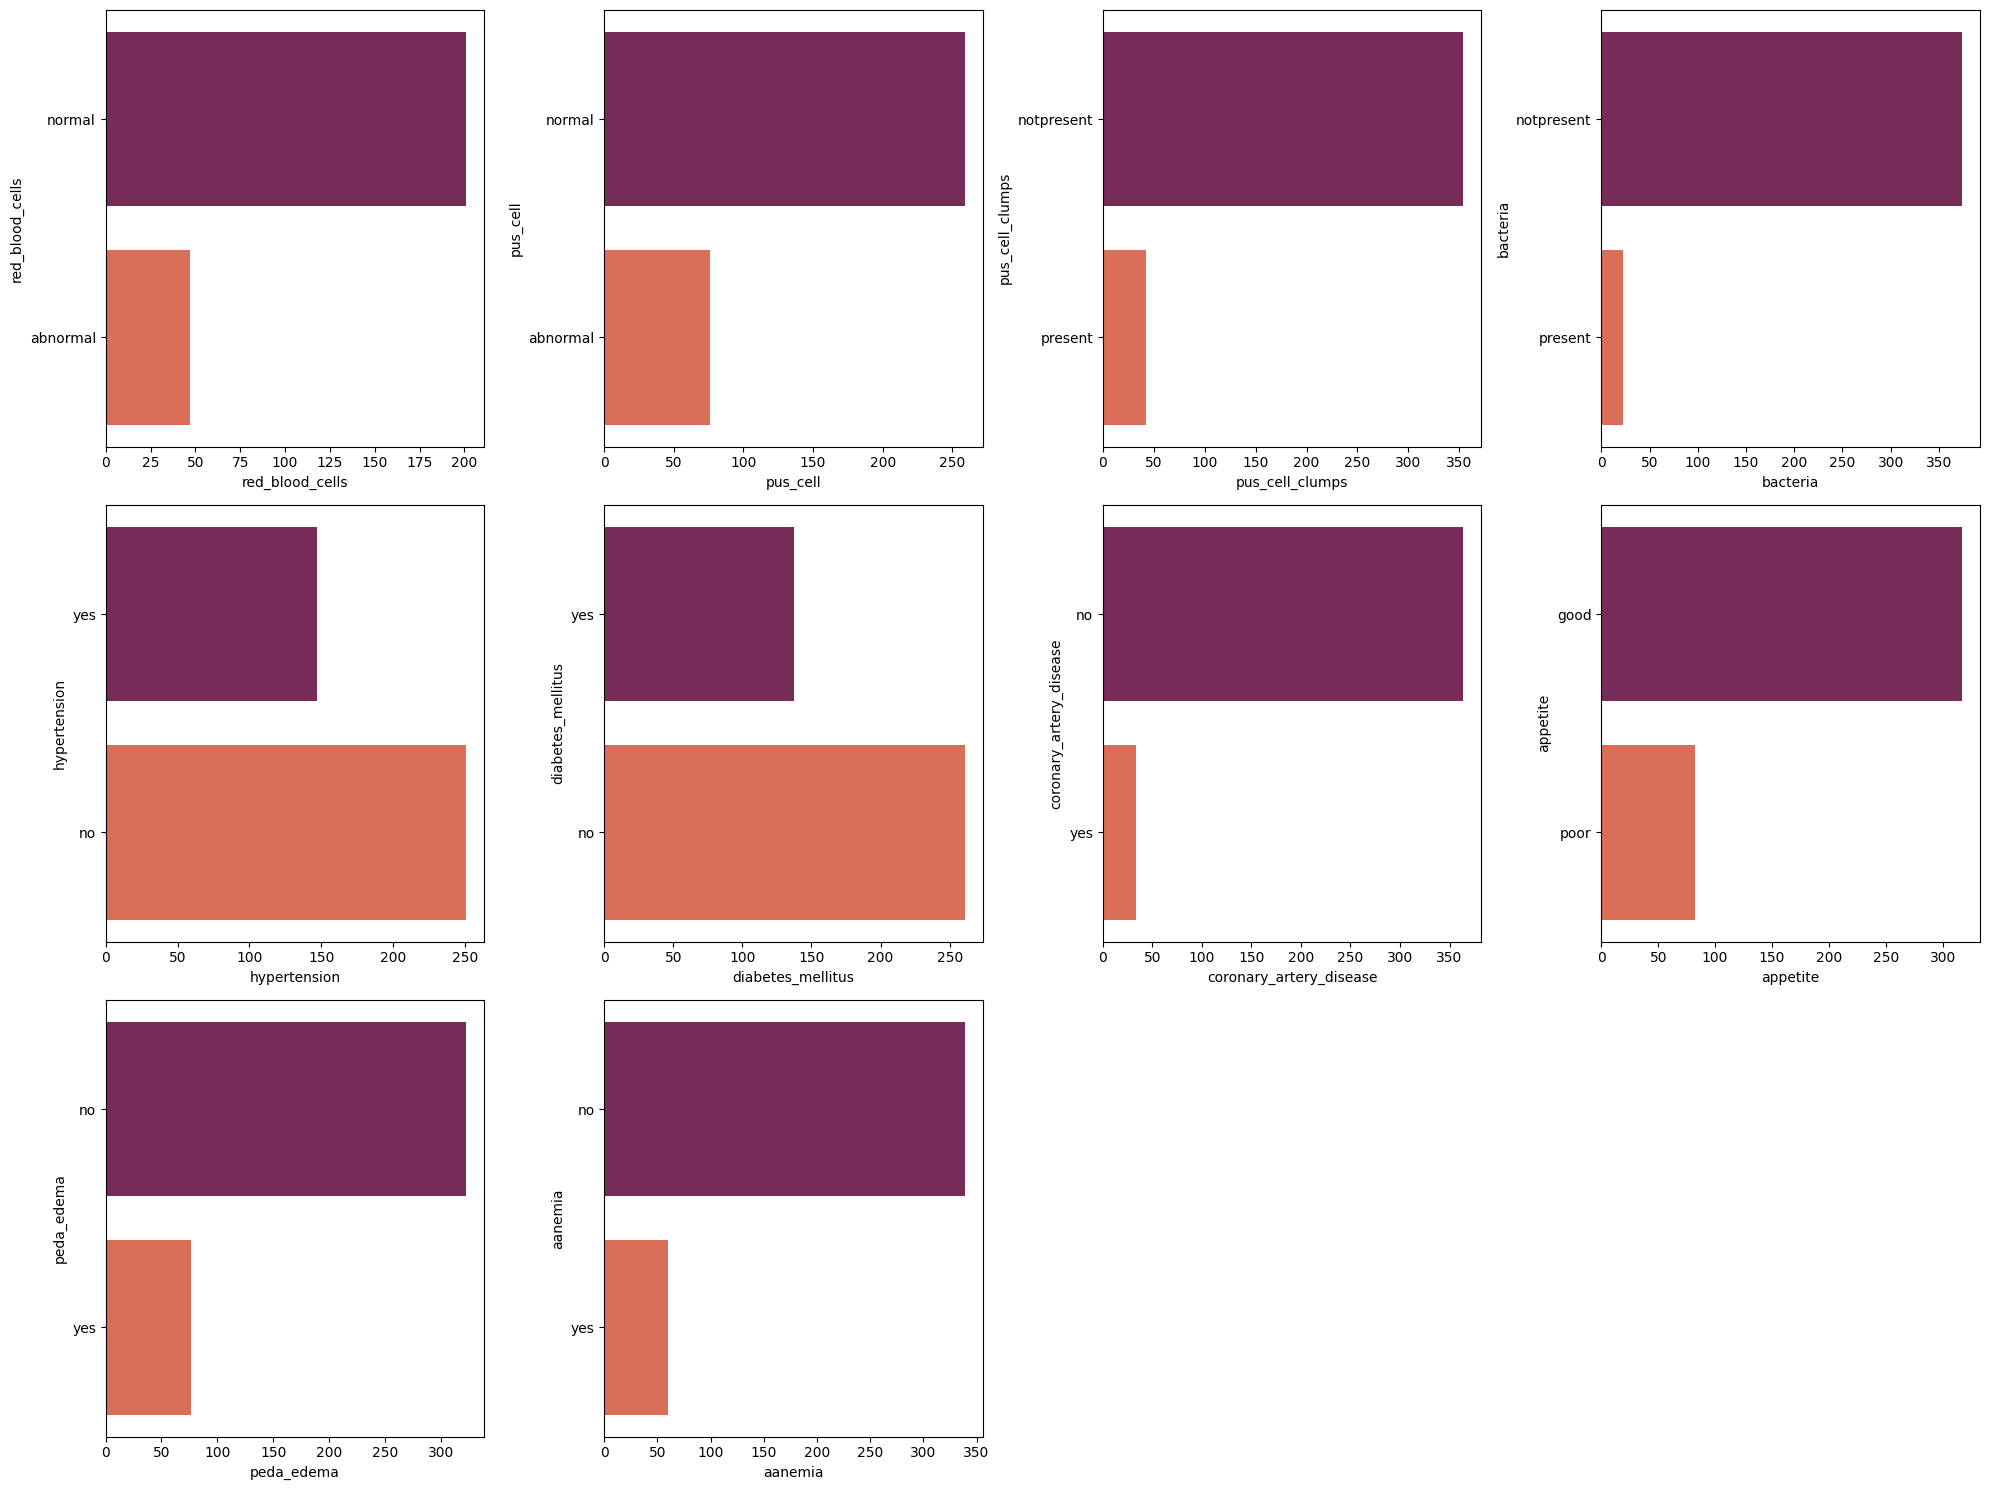

In [ ]:
# looking at categorical columns

plt.figure(figsize = (20, 15))
plotnumber = 1

for column in cat_cols:
    if plotnumber <= 11:
        ax = plt.subplot(3, 4, plotnumber)
        sns.countplot(df[column], palette = 'rocket')
        plt.xlabel(column)

    plotnumber += 1

plt.tight_layout()
plt.show()

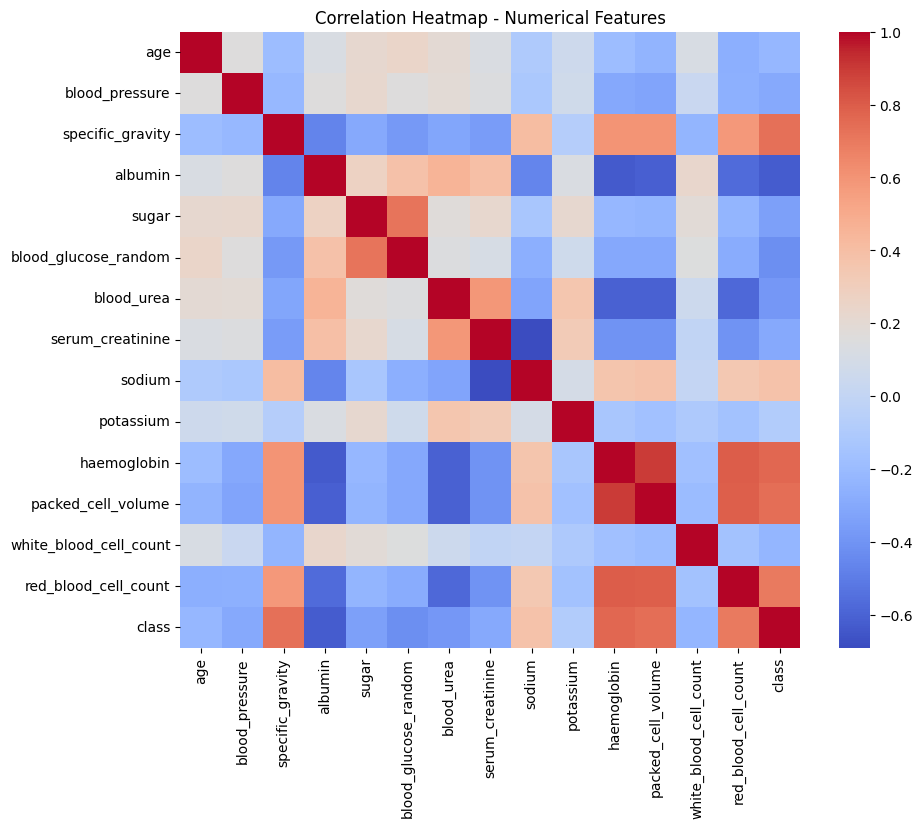

In [ ]:
# corr for numerical

plt.figure(figsize=(10,8))
sns.heatmap(df[num_cols].corr(), annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap - Numerical Features")
plt.show()


EDA

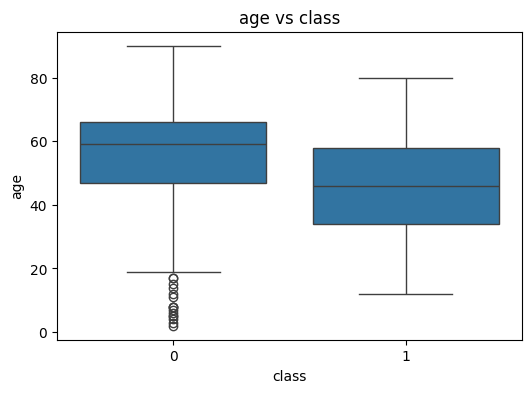

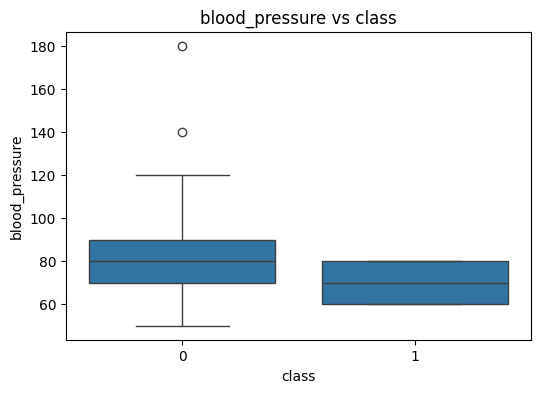

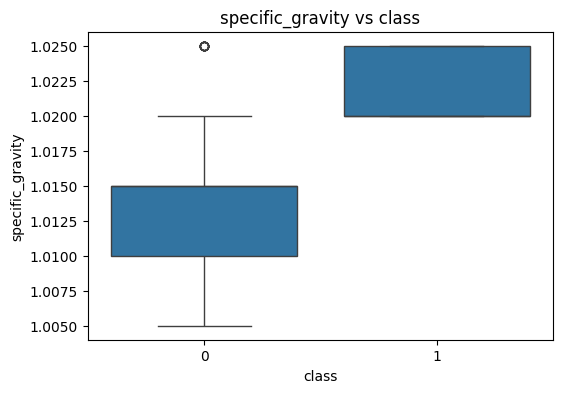

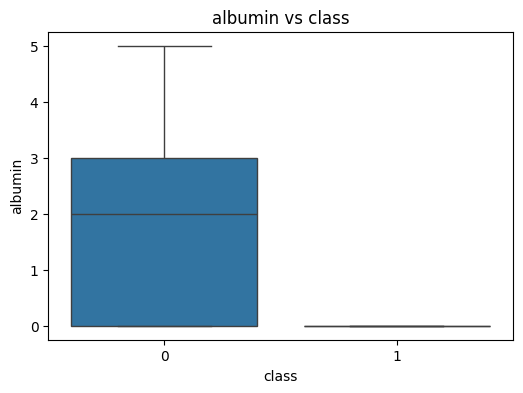

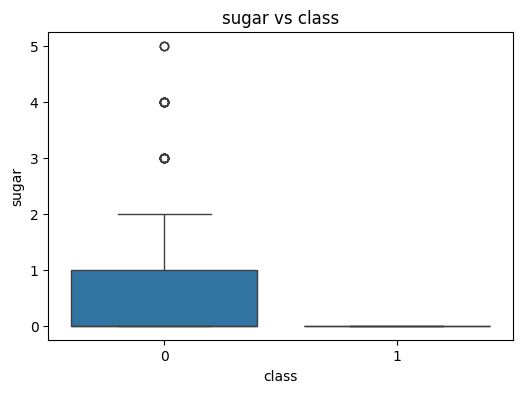

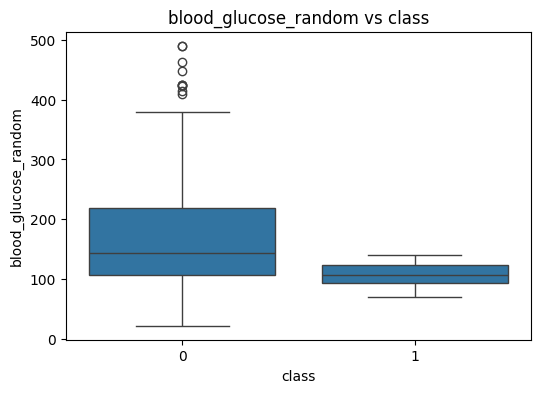

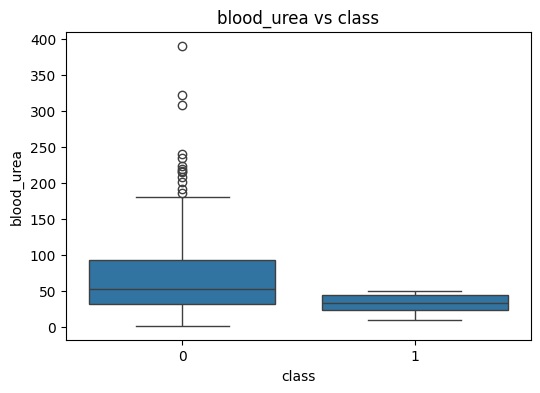

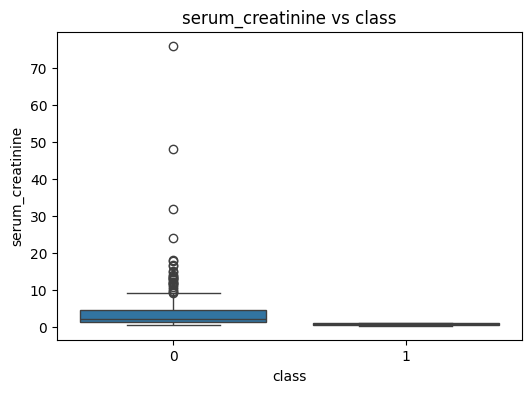

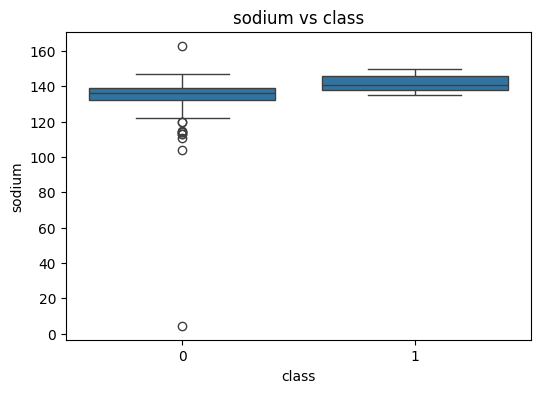

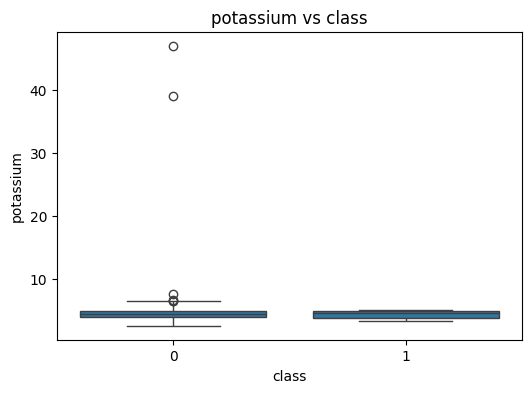

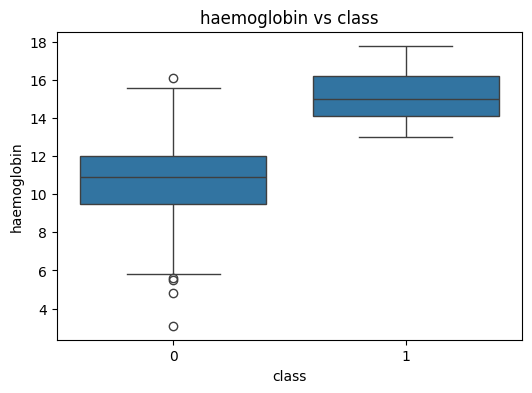

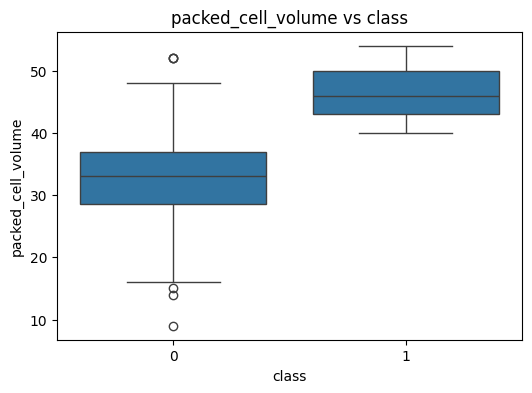

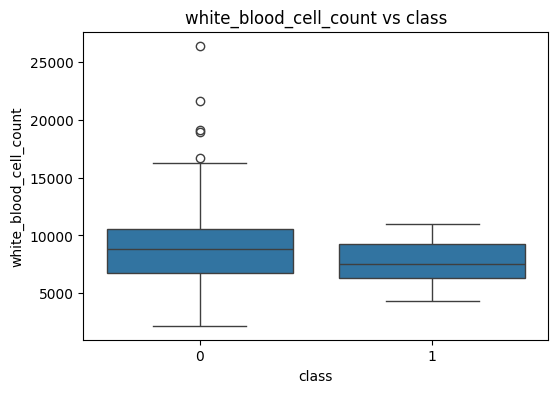

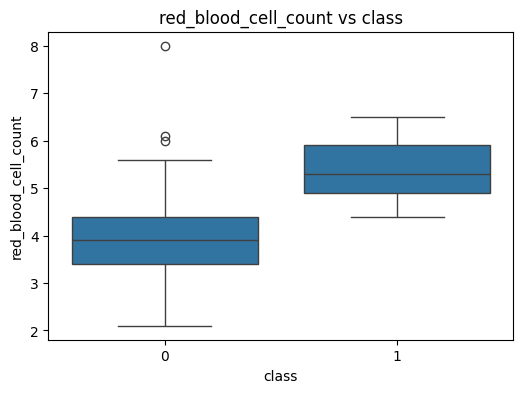

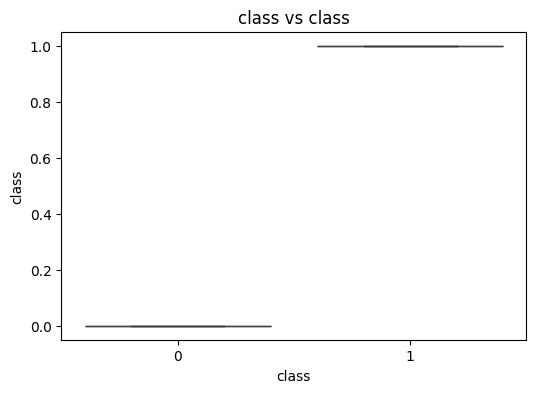

In [ ]:
#Target vs Numerical Features (Boxplots) [ Bivariate Analysis]
target = "class"

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[target], y=df[col])
    plt.title(f"{col} vs {target}")
    plt.show()


In [ ]:
# defining functions to create plot
import plotly.express as px
def violin(col):
    fig = px.violin(df, y=col, x="class", color="class", box=True, template = 'plotly_dark')
    return fig.show()


def kde(col):
    grid = sns.FacetGrid(df, hue="class", height = 6, aspect=2)
    grid.map(sns.kdeplot, col)
    grid.add_legend()

def scatter(col1, col2):
    fig = px.scatter(df, x=col1, y=col2, color="class", template = 'plotly_dark')
    return fig.show()

In [ ]:

violin('red_blood_cell_count')

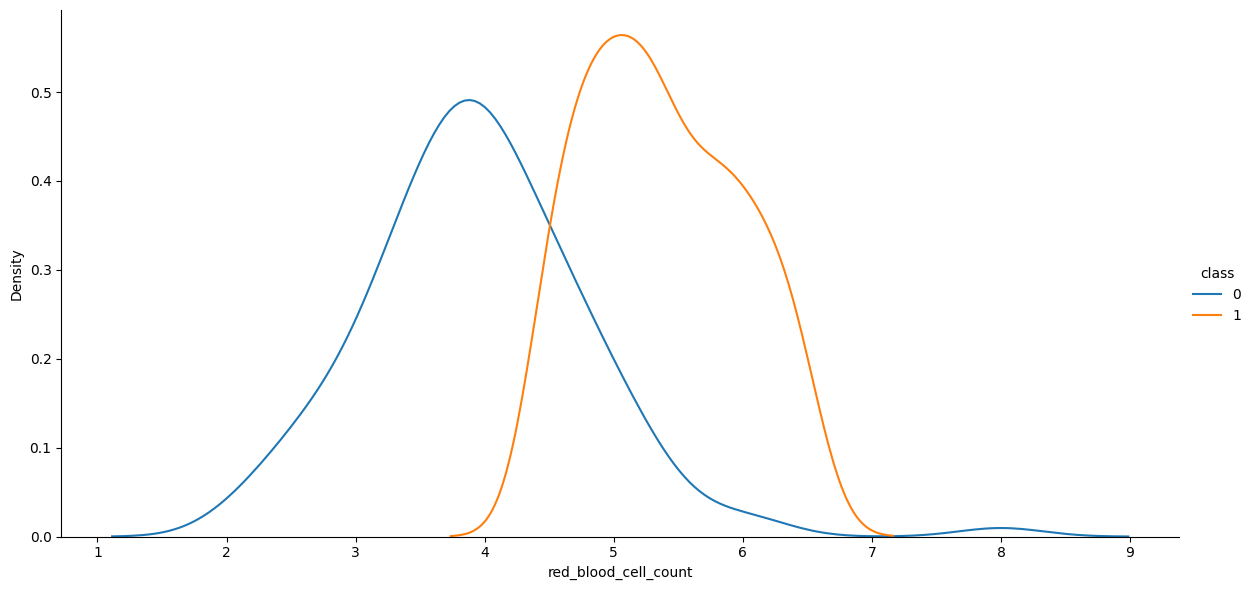

In [ ]:
kde('red_blood_cell_count')

In [ ]:
violin('white_blood_cell_count')

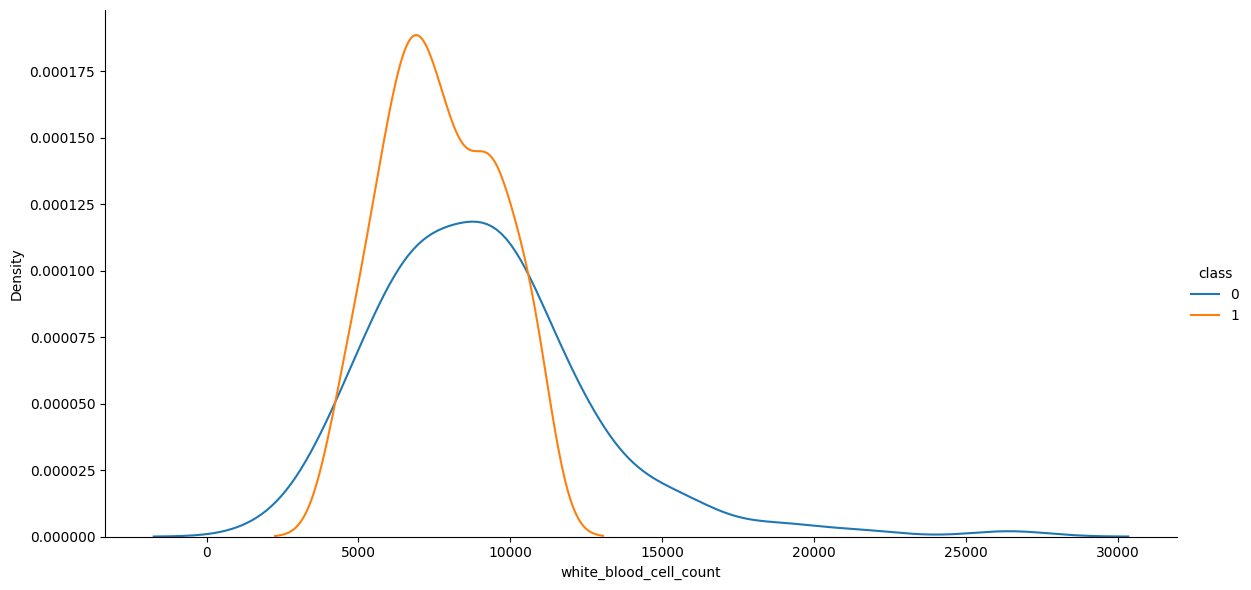

In [ ]:
kde('white_blood_cell_count')

In [ ]:
violin('packed_cell_volume')

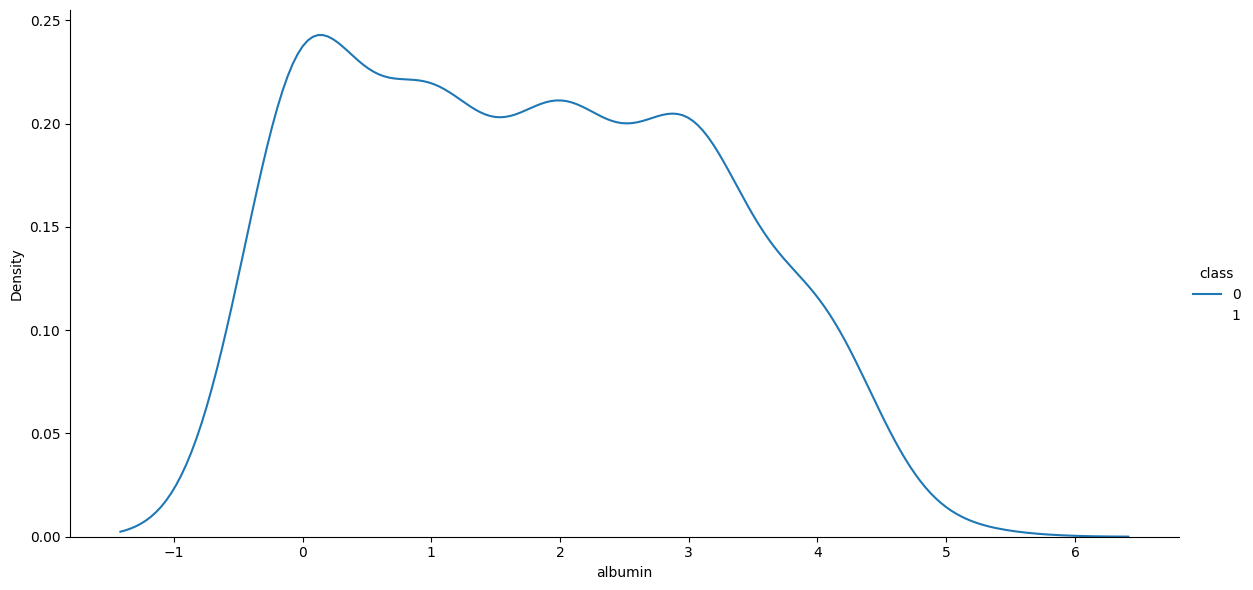

In [ ]:
kde('albumin')

In [ ]:
violin('blood_glucose_random')

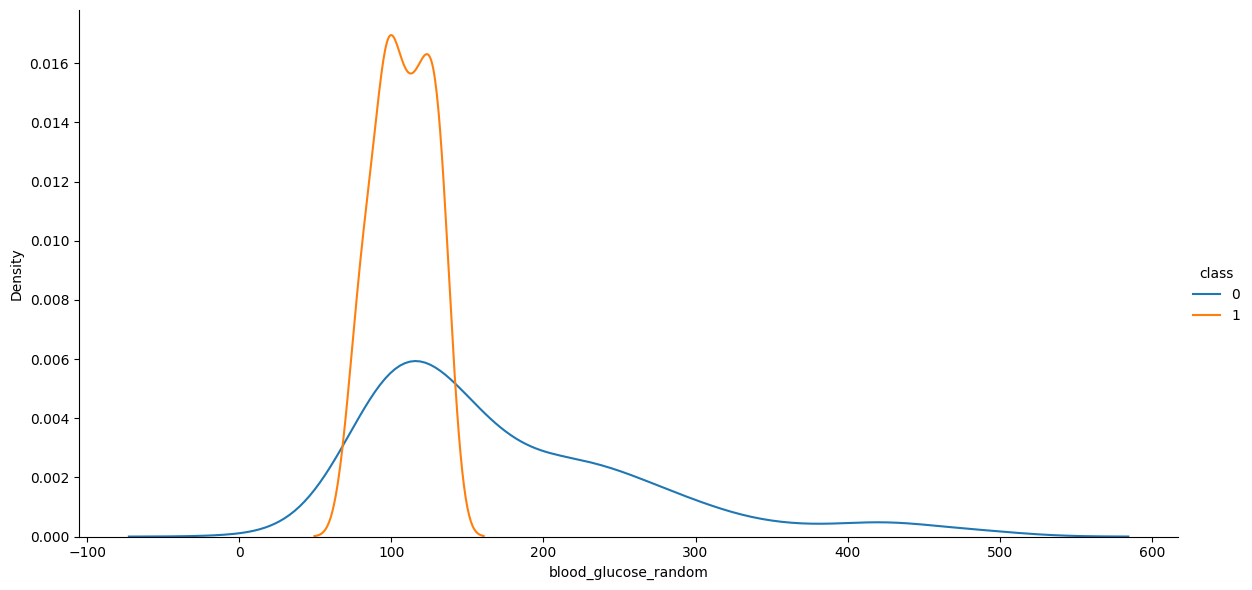

In [ ]:
kde('blood_glucose_random')

In [ ]:
scatter('haemoglobin', 'packed_cell_volume')

In [ ]:
scatter('red_blood_cell_count', 'packed_cell_volume')

In [ ]:
scatter('red_blood_cell_count', 'albumin')

In [ ]:
scatter('sugar', 'blood_glucose_random')

In [ ]:
px.bar(df, x="specific_gravity", y="packed_cell_volume", color='class', barmode='group', template = 'plotly_white', height = 400)

In [ ]:
px.bar(df, x="specific_gravity", y="albumin", color='class', barmode='group', template = 'plotly_white', height = 400)

In [ ]:
px.bar(df, x="blood_pressure", y="haemoglobin", color='class', barmode='group', template = 'plotly_dark', height = 400)

Outliers detection


In [ ]:
import numpy as np

outlier_summary = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)][col].count()
    outlier_summary[col] = outliers

pd.DataFrame(outlier_summary.items(), columns=["Feature", "Outlier Count"])


,Feature,Outlier Count
0,age,10
1,blood_pressure,36
2,specific_gravity,0
3,albumin,0
4,sugar,61
5,blood_glucose_random,34
6,blood_urea,38
7,serum_creatinine,51
8,sodium,16
9,potassium,4


<Figure size 1600x2000 with 0 Axes>

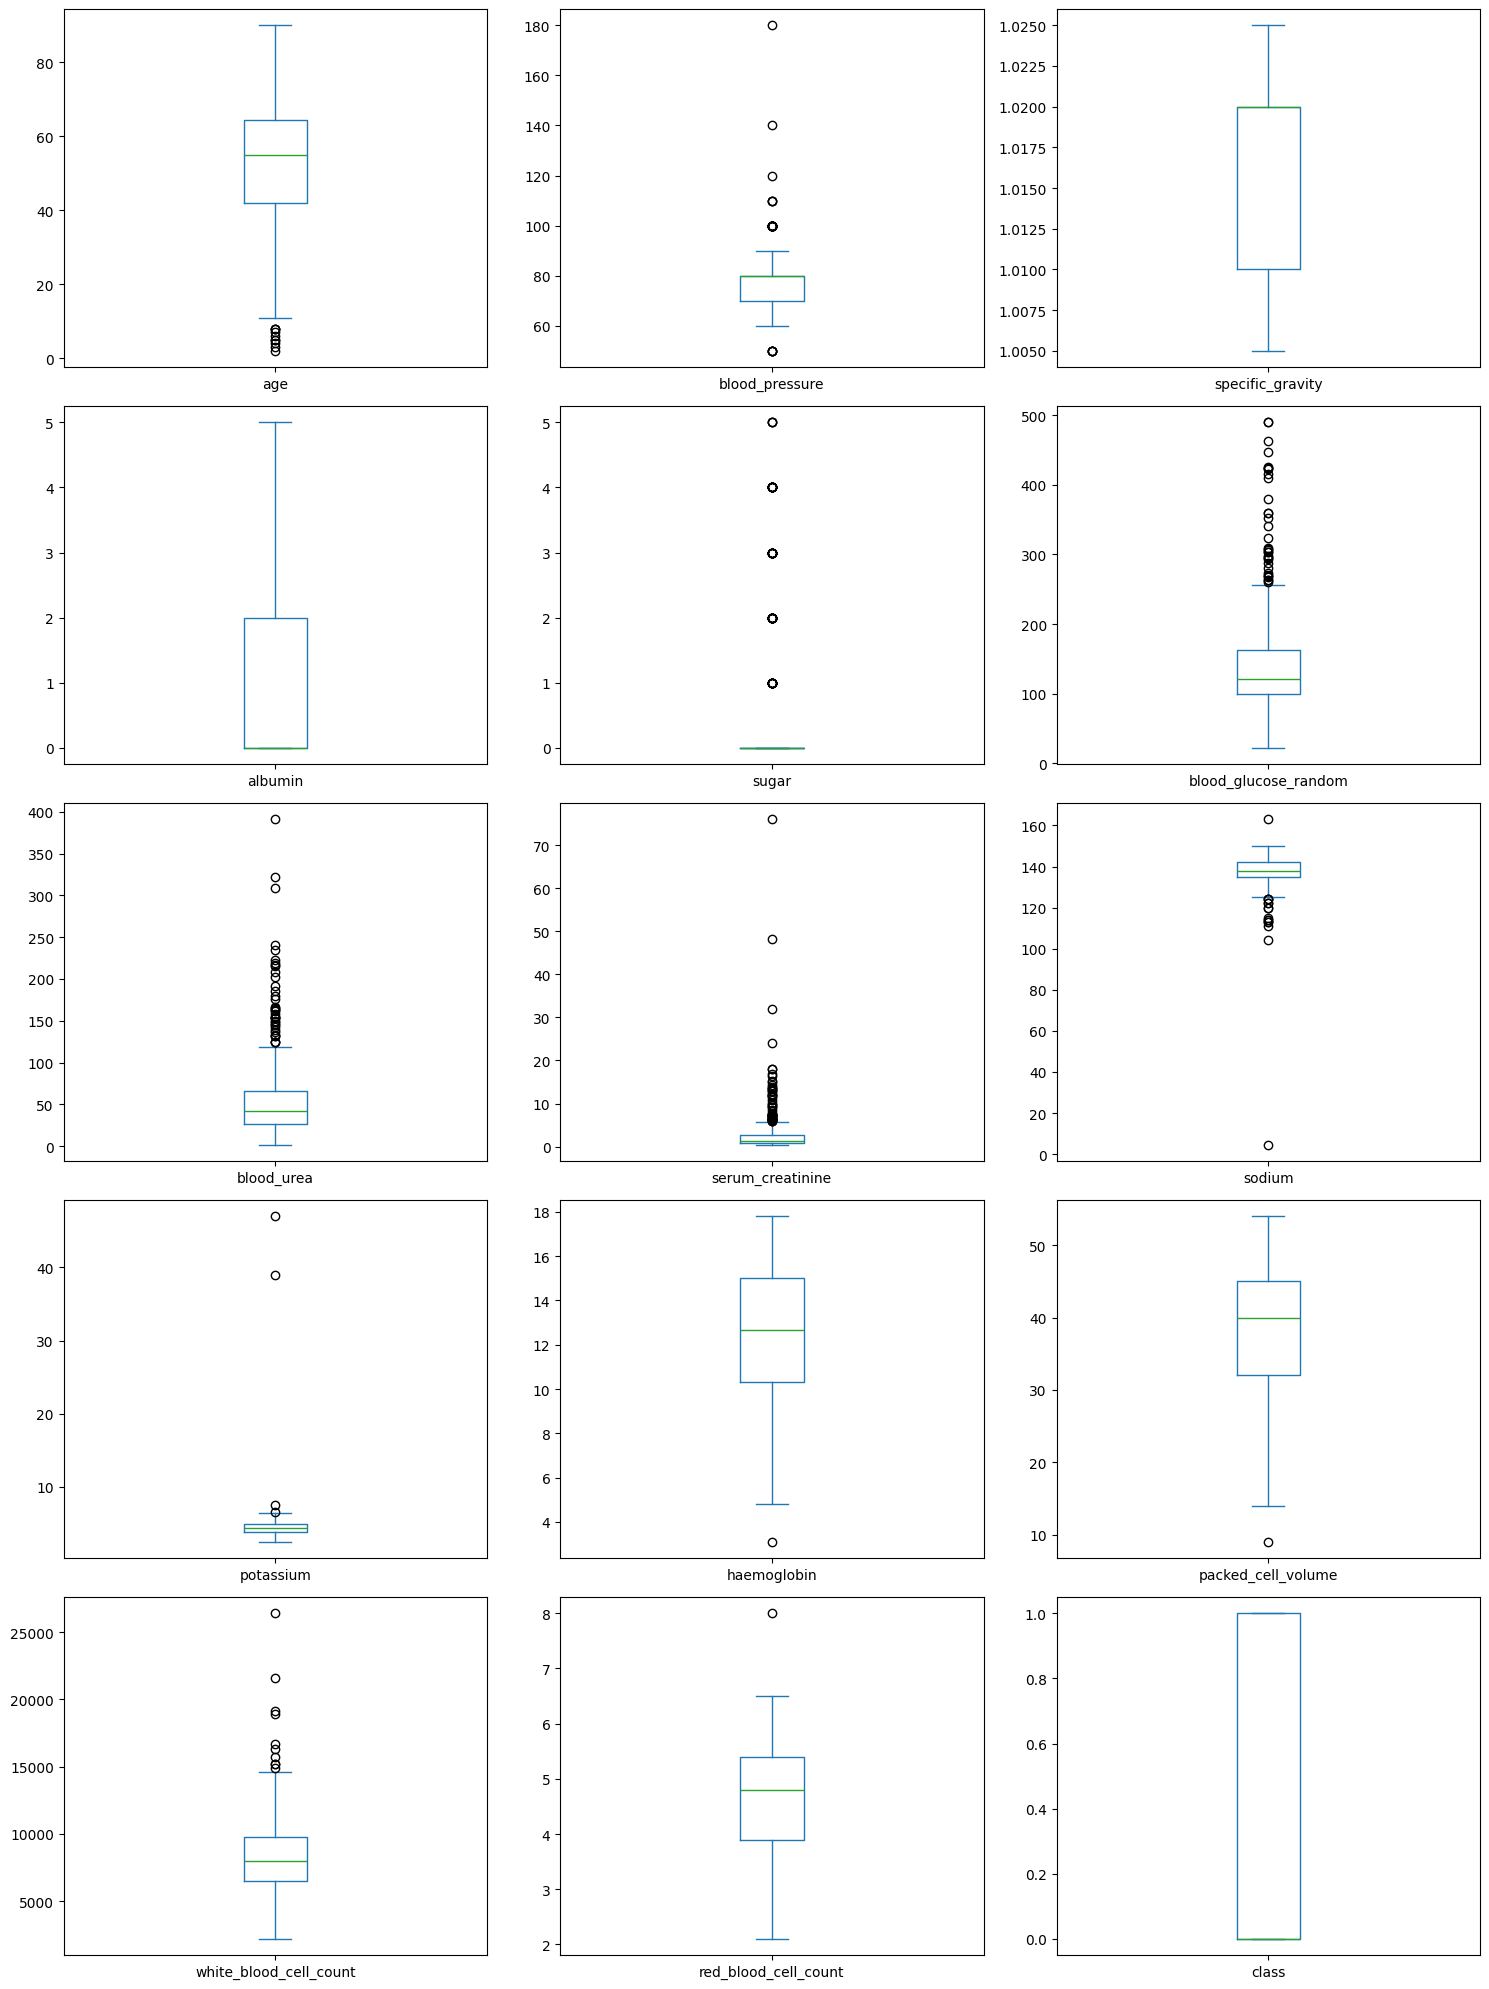

In [ ]:
plt.figure(figsize=(16,20))
df[num_cols].plot(kind='box', subplots=True, layout=(5,3), figsize=(15,20))
plt.tight_layout()
plt.show()

### **Feature Encoding**

Label encoding of categorical columns

In [ ]:
# filling null values, we will use two methods, random sampling for higher null values and
# mean/mode sampling for lower null values

def random_value_imputation(feature):
    random_sample = df[feature].dropna().sample(df[feature].isna().sum())
    random_sample.index = df[df[feature].isnull()].index
    df.loc[df[feature].isnull(), feature] = random_sample

def impute_mode(feature):
    mode = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode)

In [ ]:
# filling num_cols null values using random sampling method

for col in num_cols:
    random_value_imputation(col)

# filling "red_blood_cells" and "pus_cell" using random sampling method and rest of cat_cols using mode imputation

random_value_imputation('red_blood_cells')
random_value_imputation('pus_cell')

for col in cat_cols:
    impute_mode(col)

In [ ]:
#numeric columns → filled with median
#for col in num_cols:
    #df[col] = df[col].fillna(df[col].median())
#categorical columns → fill with mode
#for col in cat_cols:
 # df[col]=df[col].fillna(df[col].mode()[0])

In [ ]:
df.isnull().sum()


,0
age,0
blood_pressure,0
specific_gravity,0
albumin,0
sugar,0
red_blood_cells,0
pus_cell,0
pus_cell_clumps,0
bacteria,0
blood_glucose_random,0


In [ ]:
for col in cat_cols:
    print(f"{col} has {df[col].nunique()} categories\n")

red_blood_cells has 2 categories

pus_cell has 2 categories

pus_cell_clumps has 2 categories

bacteria has 2 categories

hypertension has 2 categories

diabetes_mellitus has 2 categories

coronary_artery_disease has 2 categories

appetite has 2 categories

peda_edema has 2 categories

aanemia has 2 categories



All the categorical columns have 2 categories so we can use label encoder



In [ ]:
le = LabelEncoder()
df_encoded = df.copy()

for col in cat_cols:

    df_encoded[col] = le.fit_transform(df_encoded[col])

df_encoded.head()


,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,...,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,aanemia,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,157.0,...,38.0,6000.0,3.3,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,3.7,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,0


# **MODEL BUILDING**




#* SEPARATE FEATURES + TARGET*

In [ ]:
X = df_encoded.drop(columns=['class'])
y = df_encoded['class']


In [ ]:
#checking target distribution
df_encoded['class'].value_counts()


,count
class,
0,250
1,150


# **Train–Test Split**


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("x:Train shape:", X_train.shape)
print("x:Test shape:", X_test.shape)
print("y:Train shape:",y_train.shape)
print("y:Test shape:",y_test.shape)

x:Train shape: (320, 24)
x:Test shape: (80, 24)
y:Train shape: (320,)
y:Test shape: (80,)


In [ ]:
#Scale Numeric Features

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
# Initialize SMOTE
sm = SMOTE(sampling_strategy='minority', random_state=42)

# Apply SMOTE to the new ENCODED training data
# --- Change X_train to X_train_encoded ---
X_train_resampled, y_train_resampled = sm.fit_resample(X_train_scaled, y_train)
# Note: y_train remains unchanged as it's already numeric (0s and 1s)

In [ ]:
print("Train class distribution:\n", pd.Series(y_train_resampled).value_counts())


Train class distribution:
 class
1    200
0    200
Name: count, dtype: int64


# **Training  Multiple ML Models**

KNN

In [ ]:
knn = KNeighborsClassifier()
knn.fit(X_train_resampled, y_train_resampled)
y_train_pred = knn.predict(X_train_resampled)
y_test_pred = knn.predict(X_test_scaled)

knn_acc = accuracy_score(y_test, y_test_pred)
print("Training Accuracy of KNN:", accuracy_score(y_train_resampled, y_train_pred))
print("Test Accuracy of KNN:", accuracy_score(y_test, y_test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))

Training Accuracy of KNN: 0.965
Test Accuracy of KNN: 0.9375
Confusion Matrix:
 [[45  5]
 [ 0 30]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.90      0.95        50
           1       0.86      1.00      0.92        30

    accuracy                           0.94        80
   macro avg       0.93      0.95      0.94        80
weighted avg       0.95      0.94      0.94        80



Decision Tree Classifier


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)

# accuracy score, confusion matrix and classification report of decision tree

dtc_acc = accuracy_score(y_test, dtc.predict(X_test))

print(f"Training Accuracy of Decision Tree Classifier is {accuracy_score(y_train, dtc.predict(X_train))}")
print(f"Test Accuracy of Decision Tree Classifier is {dtc_acc} \n")

print(f"Confusion Matrix :- \n{confusion_matrix(y_test, dtc.predict(X_test))}\n")
print(f"Classification Report :- \n {classification_report(y_test, dtc.predict(X_test))}")

Training Accuracy of Decision Tree Classifier is 1.0
Test Accuracy of Decision Tree Classifier is 0.9875 

Confusion Matrix :- 
[[50  0]
 [ 1 29]]

Classification Report :- 
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80



In [ ]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train_resampled, y_train_resampled)

# accuracy score, confusion matrix and classification report of decision tree
y_test_pred = dtc.predict(X_test_scaled)
dtc_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy of Decision Tree Classifier is {accuracy_score(y_train_resampled, dtc.predict(X_train_resampled))}")
print(f"Test Accuracy of Decision Tree Classifier is {dtc_acc} \n")

print(f"Confusion Matrix :- \n{confusion_matrix(y_test, dtc.predict(X_test_scaled))}\n")
print(f"Classification Report :- \n {classification_report(y_test, dtc.predict(X_test_scaled))}")

Training Accuracy of Decision Tree Classifier is 1.0
Test Accuracy of Decision Tree Classifier is 0.975 

Confusion Matrix :- 
[[49  1]
 [ 1 29]]

Classification Report :- 
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        50
           1       0.97      0.97      0.97        30

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80



In [ ]:
# hyper parameter tuning of decision tree
from sklearn.model_selection import GridSearchCV
grid_param = {
    'criterion' : ['gini', 'entropy'],
    'max_depth' : [3, 5, 7, 10],
    'splitter' : ['best', 'random'],
    'min_samples_leaf' : [ 1,2, 3, 5, 7],
    'min_samples_split' : [1, 2, 3, 5, 7],
    'max_features' : ['auto', 'sqrt', 'log2']
}

grid_search_dtc = GridSearchCV(dtc, grid_param, cv = 5, n_jobs = -1, verbose = 1)
grid_search_dtc.fit(X_train, y_train)

Fitting 5 folds for each of 1200 candidates, totalling 6000 fits


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10],
                         'max_features': ['auto', 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3, 5, 7],
                         'min_samples_split': [1, 2, 3, 5, 7],
                         'splitter': ['best', 'random']},
             verbose=1)

In [ ]:
# best parameters and best score

print(grid_search_dtc.best_params_)
print(grid_search_dtc.best_score_)

{'criterion': 'entropy', 'max_depth': 7, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'splitter': 'best'}
0.98125


In [ ]:
# Best estimator from GridSearchCV
dtc = grid_search_dtc.best_estimator_

# Predictions
y_train_pred = dtc.predict(X_train_resampled)
y_test_pred = dtc.predict(X_test_scaled)

# Accuracy
dtc_acc = accuracy_score(y_test, y_test_pred)
print("Training Accuracy of Decision Tree Classifier:", accuracy_score(y_train_resampled, y_train_pred))
print("Test Accuracy of Decision Tree Classifier:", dtc_acc)

# Confusion Matrix & Report
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))

Training Accuracy of Decision Tree Classifier: 0.5
Test Accuracy of Decision Tree Classifier: 0.625
Confusion Matrix:
 [[50  0]
 [30  0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.62      1.00      0.77        50
           1       0.00      0.00      0.00        30

    accuracy                           0.62        80
   macro avg       0.31      0.50      0.38        80
weighted avg       0.39      0.62      0.48        80



Random Forest Classifier

In [ ]:
# Fit on resampled training data
rd_clf = RandomForestClassifier(
    criterion='entropy',
    max_depth=11,
    max_features='sqrt',
    min_samples_leaf=2,
    min_samples_split=3,
    n_estimators=130,
    random_state=42
)
rd_clf.fit(X_train, y_train)




# Predictions

rd_acc = accuracy_score(y_test, rd_clf.predict(X_test))
# Accuracy
print(f"Training Accuracy of Random Forest Classifier is {accuracy_score(y_train, rd_clf.predict(X_train))}")
print(f"Test Accuracy of Random Forest Classifier is {rd_acc} \n")

# Confusion Matrix & Report
print(f"Confusion Matrix :- \n{confusion_matrix(y_test, rd_clf.predict(X_test))}\n")
print(f"Classification Report :- \n {classification_report(y_test, rd_clf.predict(X_test))}")

Training Accuracy of Random Forest Classifier is 1.0
Test Accuracy of Random Forest Classifier is 0.9875 

Confusion Matrix :- 
[[50  0]
 [ 1 29]]

Classification Report :- 
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80



Ada Boost Classifier

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
# Fit AdaBoost on resampled training data
ada = AdaBoostClassifier(estimator=dtc, random_state=42)
ada.fit(X_train_resampled, y_train_resampled)

# Predictions
y_train_pred = ada.predict(X_train_resampled)
y_test_pred = ada.predict(X_test_scaled)
ada_acc = accuracy_score(y_test, y_test_pred)
# Accuracy
print("Training Accuracy of AdaBoost Classifier:", accuracy_score(y_train_resampled, y_train_pred))
print("Test Accuracy of AdaBoost Classifier:", accuracy_score(y_test, y_test_pred))

# Confusion Matrix & Report
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))


Training Accuracy of AdaBoost Classifier: 1.0
Test Accuracy of AdaBoost Classifier: 0.9875
Confusion Matrix:
 [[50  0]
 [ 1 29]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.97      0.98        30

    accuracy                           0.99        80
   macro avg       0.99      0.98      0.99        80
weighted avg       0.99      0.99      0.99        80



Gradient Boosting Classifier

In [ ]:
gbc = GradientBoostingClassifier()

PARAMETERS = {
    'loss': ['log_loss', 'exponential'],
    'learning_rate':[0.001, 0.1, 1, 10],
    'n_estimators':[100,150,180, 200]
}
grid_search_gbc = GridSearchCV(gbc, PARAMETERS, cv=5, n_jobs=-1, verbose= 1)
grid_search_gbc.fit(X_train, y_train)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


GridSearchCV(cv=5, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.001, 0.1, 1, 10],
                         'loss': ['log_loss', 'exponential'],
                         'n_estimators': [100, 150, 180, 200]},
             verbose=1)

In [ ]:
print(grid_search_gbc.best_params_)
print(grid_search_gbc.best_score_)

{'learning_rate': 1, 'loss': 'exponential', 'n_estimators': 100}
0.96875


In [ ]:
gbc = GradientBoostingClassifier(learning_rate= 0.1, loss = 'log_loss', n_estimators = 100)
gbc.fit(X_train, y_train)

GradientBoostingClassifier()

In [ ]:

# Predictions
y_train_pred = gbc.predict(X_train_resampled)
y_test_pred = gbc.predict(X_test_scaled)
gbc_acc = accuracy_score(y_test, y_test_pred)
# Accuracy
print("Training Accuracy of GBC:", accuracy_score(y_train_resampled, y_train_pred))
print("Testing Accuracy of GBC:", accuracy_score(y_test, y_test_pred))

# Confusion Matrix & Report
print("Confusion Matrix of GBC:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report of GBC:\n", classification_report(y_test, y_test_pred))

Training Accuracy of GBC: 0.5
Testing Accuracy of GBC: 0.625
Confusion Matrix of GBC:
 [[50  0]
 [30  0]]
Classification Report of GBC:
               precision    recall  f1-score   support

           0       0.62      1.00      0.77        50
           1       0.00      0.00      0.00        30

    accuracy                           0.62        80
   macro avg       0.31      0.50      0.38        80
weighted avg       0.39      0.62      0.48        80



XgBoost


In [ ]:
from xgboost import XGBClassifier

# Train on resampled training data
xgb = XGBClassifier(objective='binary:logistic', learning_rate=0.5, max_depth=5, n_estimators=150, random_state=42)
xgb.fit(X_train_resampled, y_train_resampled)


# Predictions
y_train_pred = xgb.predict(X_train_resampled)
y_test_pred = xgb.predict(X_test_scaled)
xgb_acc = accuracy_score(y_test, y_test_pred)
# Accuracy
print("Training Accuracy of XGBoost:", accuracy_score(y_train_resampled, y_train_pred))
print("Test Accuracy of XGBoost:", accuracy_score(y_test, y_test_pred))

# Confusion Matrix & Report
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))


Training Accuracy of XGBoost: 1.0
Test Accuracy of XGBoost: 0.975
Confusion Matrix:
 [[49  1]
 [ 1 29]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        50
           1       0.97      0.97      0.97        30

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80



SVM

In [ ]:
svm  = SVC( probability=True)
parameter = {
    'gamma':[0.0001, 0.001, 0.01, 0.1],
    'C':[0.01, 0.05, 0.5, 0.1, 1, 10, 15, 20]
}
svm.fit(X_train, y_train)
grid_search = GridSearchCV(svm, parameter)
grid_search.fit(X_train, y_train)


GridSearchCV(estimator=SVC(probability=True),
             param_grid={'C': [0.01, 0.05, 0.5, 0.1, 1, 10, 15, 20],
                         'gamma': [0.0001, 0.001, 0.01, 0.1]})

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'C': 10, 'gamma': 0.0001}
0.7625


In [ ]:
svm  = SVC(gamma = 0.0001, C  = 15, probability=True)
svm.fit(X_train, y_train)

SVC(C=15, gamma=0.0001, probability=True)

In [ ]:

# Predictions
y_train_pred = svm.predict(X_train_resampled)
y_test_pred = svm.predict(X_test_scaled)
svm_acc = accuracy_score(y_test, y_test_pred)
# Accuracy
print("Training Accuracy of svc:", accuracy_score(y_train_resampled, y_train_pred))
print("Test Accuracy of svc:", accuracy_score(y_test, y_test_pred))

# Confusion Matrix & Report
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))




Training Accuracy of svc: 0.5
Test Accuracy of svc: 0.625
Confusion Matrix:
 [[50  0]
 [30  0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.62      1.00      0.77        50
           1       0.00      0.00      0.00        30

    accuracy                           0.62        80
   macro avg       0.31      0.50      0.38        80
weighted avg       0.39      0.62      0.48        80



Models Comparison

In [ ]:
models = pd.DataFrame({
    'Model': [
        'KNN',
        'Decision Tree Classifier',
        'Random Forest Classifier',
        'Ada Boost Classifier',
        'Gradient Boosting Classifier',
        'SVM',
        'XgBoost'
    ],
    'Score': [knn_acc, dtc_acc, rd_acc, ada_acc, gbc_acc, svm_acc, xgb_acc]
})

# Sort and display
models.sort_values(by='Score', ascending=False)


,Model,Score
2,Random Forest Classifier,0.9875
3,Ada Boost Classifier,0.9875
6,XgBoost,0.9750
0,KNN,0.9375
1,Decision Tree Classifier,0.6250
4,Gradient Boosting Classifier,0.6250
5,SVM,0.6250


In [ ]:
px.bar(data_frame = models, x = 'Score', y = 'Model', color = 'Score', template = 'plotly_dark',
       title = 'Models Comparison')

Save the Final Model

In [ ]:
model_objects = {
    'KNN': knn,
    'Decision Tree Classifier': dtc,
    'Random Forest Classifier': rd_clf,
    'Ada Boost Classifier': ada,
    'Gradient Boosting Classifier': gbc,
    'SVM': svm,
    'XgBoost': xgb
}

In [ ]:
# Get the row index of the best model based on Score
best_idx = models['Score'].idxmax()

# Get best model name and score
best_model_name = models.loc[best_idx, 'Model']
best_model_score = models.loc[best_idx, 'Score']

print("Best model:", best_model_name)
print("Best score:", best_model_score)

# Get the actual trained model object
best_model = model_objects[best_model_name]

Best model: Random Forest Classifier
Best score: 0.9875


In [ ]:
import pickle

# Save best model
with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print("Best model saved as best_model.pkl")

Best model saved as best_model.pkl
